# DSMarket — Segmentación de productos (Tarea 2)

**De:** Nicole, Data Science
**Para:** Joelle (Marketing Manager), Michelle (Chief Digital Officer)

Joelle planteó dos cuestiones:

1. **Agrupar productos que se comporten de manera similar**, para evaluar las campañas por grupo y no producto a producto. Se consultó cuántos grupos utilizar: ¿5, 10 o 20?
2. Determinar si **un enfoque similar es válido para comparar tiendas**.

Este notebook responde a ambas:

- Para los productos se emplea **K-Means**, y el número de grupos se elige con el **método del codo** (probando de 2 a 14 grupos), apoyado en la **silueta**. El resultado es **una única segmentación**, y cada grupo recibe un nombre que describe su comportamiento de compra.
- Para las tiendas **no se aplica un algoritmo de agrupamiento**: con solo 10 tiendas, la comparación se realiza directamente. La sección 5 explica el motivo.

Se parte de las mismas fuentes y decisiones de limpieza del EDA (`01_EDA_DSMarket.ipynb`, sección 6).

## 1. Configuración e imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA
from scipy.spatial.distance import cdist
import os

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
RANDOM_STATE = 42
%matplotlib inline

## 2. Paleta de marca DSMarket

Se utiliza la misma paleta validada del EDA (sección 2 de `01_EDA_DSMarket.ipynb`), repetida aquí para que el notebook pueda ejecutarse por separado.

In [2]:
DSMARKET_NAVY = "#0a2a5c"
DSMARKET_BLUE = "#2a78d6"
DSMARKET_GOLD = "#eda100"
DSMARKET_GREEN = "#6a9f1f"

DSMARKET_BLUE_RAMP = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#2a78d6", "#1c5cab", "#0d366b"]
dsmarket_blues_cmap = LinearSegmentedColormap.from_list("dsmarket_blues", DSMARKET_BLUE_RAMP)
DIVERGENTE = LinearSegmentedColormap.from_list("dsmarket_div", [DSMARKET_GOLD, "#ffffff", DSMARKET_BLUE])

# un color por grupo de producto (6 grupos)
CLUSTER_PALETTE = [DSMARKET_BLUE, DSMARKET_GREEN, DSMARKET_NAVY, DSMARKET_GOLD, "#8a5fd6", "#d65f8a"]

sns.set_theme(style="whitegrid", rc={
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#0b0b0b", "text.color": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "grid.color": "#e1e0d9",
    "figure.facecolor": "white", "axes.facecolor": "white",
})
plt.rcParams["axes.titlecolor"] = DSMARKET_NAVY
plt.rcParams["axes.titleweight"] = "bold"

## 3. Carga de datos

Se aplican las mismas decisiones que en el EDA: las filas de `item_prices.csv` sin `yearweek` (precios de las 8 semanas posteriores al final de las ventas) se excluyen de este análisis, que es histórico; se conservan como precios del horizonte de predicción para la Tarea 3. Las 1.913 columnas de días se almacenan como `int16` (el máximo vendido en un día es 763), lo que reduce la memoria a la cuarta parte.

El día de la semana se obtiene **de la fecha** (`dt.weekday`, 0 = lunes), y no de la columna `weekday_int` del calendario, que numera la semana de sábado (1) a viernes (7).

In [3]:
DATA_DIR = "data_dsmarket/data_dsmarket"

sales = pd.read_csv(f"{DATA_DIR}/item_sales.csv")
calendar = pd.read_csv(f"{DATA_DIR}/daily_calendar_with_events.csv")
calendar['date'] = pd.to_datetime(calendar['date'])

day_cols = [c for c in sales.columns if c.startswith('d_')]
sales[day_cols] = sales[day_cols].astype('int16')

prices = pd.read_csv(f"{DATA_DIR}/item_prices.csv")
prices_clean = prices.dropna(subset=['yearweek'])
prices_clean = prices_clean.assign(yearweek=prices_clean['yearweek'].astype(int))
del prices

dates_of_days = calendar.set_index('d')['date'].loc[day_cols]
weekdays = dates_of_days.dt.weekday.values      # 0 = lunes ... 6 = domingo
months = dates_of_days.dt.month.values
is_weekend = np.isin(weekdays, [5, 6])          # sábado y domingo
is_dec = months == 12

print(f"sales: {sales.shape} | prices_clean: {prices_clean.shape} | calendar: {calendar.shape}")

sales: (30490, 1920) | prices_clean: (6721786, 5) | calendar: (1913, 5)


## 4. Segmentación de productos

### 4.1. Variables de negocio

Primero, es necesario traducir cómo se vende un producto a números. Para cada uno de los 3.049 productos se suman las 10 tiendas y se cuenta **solo desde el día de su primera venta**: muchos productos se incorporaron al catálogo a mitad del periodo, y contar los días anteriores como «días sin venta» confundiría un lanzamiento tardío con un producto de compra ocasional.

| Variable | Pregunta que responde |
|---|---|
| `log_units_dia` | ¿Cuánto vende al día desde que está a la venta? (en logaritmo, porque hay productos que venden 100 veces más que otros) |
| `cv_daily` | ¿Vende de forma estable o a saltos? (coeficiente de variación diario) |
| `zero_frac` | ¿Qué % de los días en que está a la venta no vende nada? |
| `weekend_lift` | ¿Cuánto más vende en fin de semana que entre semana? |
| `dec_lift` | ¿Cuánto más vende en diciembre que el resto del año? |
| `event_lift` | ¿Cuánto más vende en SuperBowl, Easter y Labor Day que en un día normal? |
| `trend` | ¿Sus ventas suben o bajan con los años? |
| `avg_price` | ¿Es caro o barato? |

Se adoptan dos decisiones sobre `event_lift`, ambas coherentes con el calendario extendido definido en el EDA (sección 11.2):
- **Numerador: días de SuperBowl, Easter y Labor Day.** La variable mide cómo vende cada producto esos días frente a un día normal. A la hora de interpretarla, es necesario tener en cuenta que, en el total de la empresa, solo Labor Day es un pico propio y, además, SuperBowl y Easter caen en domingo y venden como un domingo normal o menos (EDA, 11.2 c). Por eso `event_lift` recoge en parte el efecto fin de semana. Christmas forma parte del calendario extendido, pero es un día de cierre (16 unidades vendidas) y su efecto es una caída, no un pico; Thanksgiving también vende menos de lo normal. Incluirlos rebajaría el cociente de todos los productos. El efecto de la Navidad sobre cada producto queda recogido por `dec_lift`.
- **Denominador: días sin ningún evento del calendario extendido** (se excluyen también Christmas, Thanksgiving, NewYear y Ramadan starts), para que los días de cierre o atípicos no rebajen la referencia.

La categoría y el departamento **no se utilizan para agrupar**: el objetivo es agrupar por comportamiento. Se emplean después, en la ficha de los grupos (4.6), para describirlos.

In [4]:
item_day = sales.groupby('item')[day_cols].sum()
vals = item_day.values.astype(float)

event_series = calendar.set_index('d')['event'].loc[day_cols]
labor_days = set()                               # Labor Day: primer lunes de septiembre
for y in dates_of_days.dt.year.unique():
    d = pd.Timestamp(year=int(y), month=9, day=1)
    while d.weekday() != 0:
        d += pd.Timedelta(days=1)
    labor_days.add(d)

# Días de SuperBowl, Easter y Labor Day (EDA, 11.2). Solo Labor Day es un pico propio; los otros dos caen en domingo (ver 4.1).
# Christmas (cierre) y Thanksgiving (caída) no se incluyen.
is_peak_event = event_series.isin(['SuperBowl', 'Easter']).values | dates_of_days.isin(labor_days).values
# Referencia: días sin ningún evento del calendario extendido (incluye Christmas).
is_any_event = (event_series.notna().values | dates_of_days.isin(labor_days).values
                | (dates_of_days.dt.month.eq(12) & dates_of_days.dt.day.eq(25)).values)
is_normal_day = ~is_any_event

# Cada producto se mide solo desde su primera venta: antes no estaba a la venta, y contar esos
# días como "sin venta" confundiría un lanzamiento tardío con un producto de compra ocasional.
primer_dia = (vals > 0).argmax(axis=1)
activo = np.arange(vals.shape[1])[None, :] >= primer_dia[:, None]
va = np.where(activo, vals, np.nan)                 # NaN = el producto aún no estaba a la venta

def media(mascara):
    return np.nanmean(np.where(mascara[None, :], va, np.nan), axis=1)

media_dia = np.nanmean(va, axis=1)
x = np.arange(vals.shape[1])
x_c = np.where(activo, x - np.nanmean(np.where(activo, x, np.nan), axis=1, keepdims=True), np.nan)

item_feat = pd.DataFrame({
    'total_units': vals.sum(axis=1),
    'dias_activo': activo.sum(axis=1),
    'units_dia': media_dia,
    'cv_daily': np.nanstd(va, axis=1) / media_dia,
    'zero_frac': np.nansum(va == 0, axis=1) / activo.sum(axis=1),
    'weekend_lift': media(is_weekend) / media(~is_weekend),
    'dec_lift': media(is_dec) / media(~is_dec),
    'event_lift': media(is_peak_event) / media(is_normal_day),
    'trend': np.nansum(np.nan_to_num(va) * np.nan_to_num(x_c), axis=1) / np.nansum(x_c ** 2, axis=1) / media_dia,
}, index=item_day.index)
item_feat['avg_price'] = prices_clean.groupby('item')['sell_price'].mean()
item_feat['log_units_dia'] = np.log1p(item_feat['units_dia'])
item_feat['facturacion'] = item_feat['total_units'] * item_feat['avg_price']   # aproximada: unidades x precio medio
print(f"Días antes de la primera venta: {(1 - activo.mean()) * 100:.1f} % de todos los días-producto")
print(f"Productos sin ningún diciembre a la venta: {int(item_feat['dec_lift'].isna().sum())}; sin eventos: {int(item_feat['event_lift'].isna().sum())}")

item_meta = sales[['item', 'category', 'department']].drop_duplicates().set_index('item')
# un producto lanzado después del último diciembre (o de los eventos) no tiene con qué compararse: se le asigna 1 (sin efecto)
item_feat[['dec_lift', 'event_lift', 'weekend_lift']] = item_feat[['dec_lift', 'event_lift', 'weekend_lift']].fillna(1.0)
item_feat = item_feat.join(item_meta).dropna(subset=['avg_price'])

CANDIDATAS = ['log_units_dia', 'cv_daily', 'zero_frac', 'weekend_lift', 'dec_lift', 'event_lift', 'trend', 'avg_price']
print(f"Productos con todas las variables: {len(item_feat)} de {sales['item'].nunique()}")
item_feat[CANDIDATAS].describe().round(2)

Días antes de la primera venta: 17.8 % de todos los días-producto
Productos sin ningún diciembre a la venta: 0; sin eventos: 0
Productos con todas las variables: 3049 de 3049


,log_units_dia,cv_daily,zero_frac,weekend_lift,dec_lift,event_lift,trend,avg_price
count,3049.00,3049.00,3049.00,3049.00,3049.00,3049.00,3049.0,3049.00
mean,2.11,0.76,0.15,1.32,0.95,1.14,0.0,5.57
std,0.92,0.27,0.14,0.13,0.32,0.28,0.0,4.54
min,0.30,0.21,0.00,0.80,0.00,0.00,-0.0,0.24
25%,1.44,0.57,0.03,1.24,0.82,0.98,-0.0,2.63
50%,1.99,0.71,0.10,1.32,0.94,1.12,-0.0,4.19
75%,2.65,0.90,0.22,1.40,1.07,1.27,0.0,7.19
max,6.26,2.69,0.80,1.91,7.66,3.66,0.0,39.49


### 4.2. Revisión de variables: ¿alguna repite información?

Si dos variables miden casi lo mismo, esa idea cuenta **doble** en la distancia que utiliza K-Means y desequilibra el agrupamiento. Se revisa la correlación entre las 8 variables candidatas.

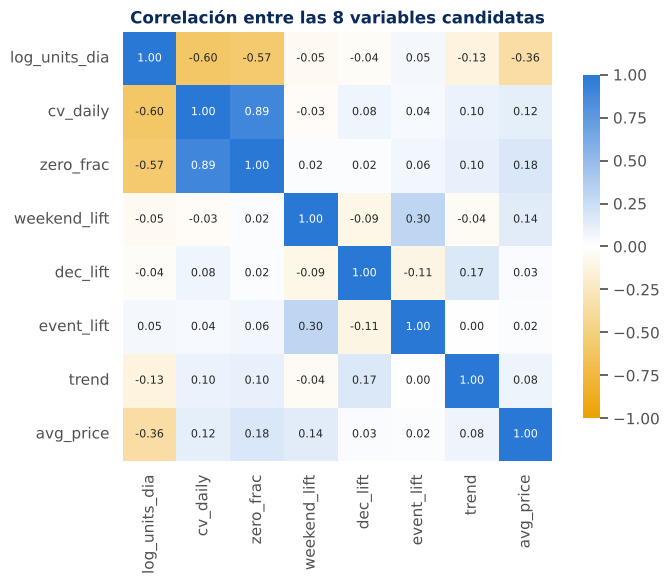

,level_0,level_1,correlacion
10,cv_daily,zero_frac,0.89
1,log_units_dia,cv_daily,-0.60
2,log_units_dia,zero_frac,-0.57
7,log_units_dia,avg_price,-0.36


In [5]:
corr = item_feat[CANDIDATAS].corr()

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap=DIVERGENTE, center=0, vmin=-1, vmax=1,
            square=True, cbar_kws={'shrink': 0.8}, ax=ax, annot_kws={'size': 8})
ax.set_title('Correlación entre las 8 variables candidatas')
plt.tight_layout()
plt.show()

pares = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename('correlacion').reset_index().assign(abs=lambda d: d['correlacion'].abs())
         .sort_values('abs', ascending=False).drop(columns='abs').head(4))
pares.round(2)

**Decisión: se eliminan `cv_daily` y `trend`, y se agrupa con 6 variables.**

- **`cv_daily` y `zero_frac` presentan una correlación de 0,89**: miden prácticamente lo mismo. Un producto que muchos días no vende nada es, por necesidad, un producto que vende a saltos. Se conserva `zero_frac` porque se explica mejor a negocio («% de días sin venta»).
- **`trend` se excluye por otro motivo.** Medida desde el lanzamiento de cada producto, ya no repite ninguna otra variable (su correlación más alta es 0,17). Sin embargo, describe el ciclo de vida del producto (si crece o decae), no *cuándo y cómo* se compra, que es lo que necesita marketing para diseñar campañas. La tendencia ya la recoge el modelo de predicción de la Tarea 3 mediante sus medias móviles.

**Por qué es relevante medir desde el lanzamiento:** el 17,8 % de los días-producto son anteriores a la primera venta de cada producto. En una primera versión se contabilizaban como «días sin venta», lo que hacía que `trend` y `zero_frac` tuvieran una correlación de 0,81: ambas medían sobre todo *cuándo llegó el producto al catálogo*, y no cómo se vende.

Con `cv_daily` incluida, la idea de «vende a saltos» contaría dos veces en la distancia. El resto de pares presenta correlaciones bajas, por lo que cada variable aporta información propia.

In [6]:
FEAT_COLS = ['log_units_dia', 'zero_frac', 'weekend_lift', 'dec_lift', 'event_lift', 'avg_price']
print(f"Variables finales ({len(FEAT_COLS)}): {FEAT_COLS}")

Variables finales (6): ['log_units_dia', 'zero_frac', 'weekend_lift', 'dec_lift', 'event_lift', 'avg_price']


### 4.3. Escalado: StandardScaler frente a RobustScaler

K-Means utiliza distancias, por lo que todas las variables deben estar en la misma escala. De lo contrario, el precio (de 0,2 a 40 $) pesaría mucho más que un ratio que va de 0 a 2.

`RobustScaler` escala con la mediana y los cuantiles para reducir la influencia de los valores extremos. Aquí existen valores extremos claros, como un producto que vende 7,7 veces más en diciembre que el resto del año, por lo que se prueban ambos escaladores en todo el rango de K.

In [7]:
ESCALADORES = {'StandardScaler': StandardScaler(), 'RobustScaler': RobustScaler()}
K_RANGO = range(2, 15)

curvas = []
for nombre, esc in ESCALADORES.items():
    X = esc.fit_transform(item_feat[FEAT_COLS].values)
    for k in K_RANGO:
        km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=50).fit(X)
        tamanos = np.bincount(km.labels_)
        curvas.append({'escalador': nombre, 'k': k, 'inercia': km.inertia_,
                       'silueta': silhouette_score(X, km.labels_),
                       'grupo_mas_pequeno': tamanos.min()})
curvas = pd.DataFrame(curvas)
curvas.pivot(index='k', columns='escalador', values='grupo_mas_pequeno').rename_axis(columns='productos en el grupo más pequeño')

productos en el grupo más pequeño,RobustScaler,StandardScaler
k,,
2,939,1182
3,276,654
4,201,263
5,100,243
6,92,120
7,75,89
8,1,74
9,1,71
10,1,70


**Decisión: `StandardScaler`.**

`RobustScaler` produce el efecto contrario al buscado. Al escalar con la mediana y los cuantiles, los valores extremos quedan todavía más alejados del resto, y **a partir de K = 8 K-Means los aísla en grupos de un solo producto**. Con `StandardScaler`, todos los grupos presentan un tamaño razonable en la zona donde se elegirá K (entre 5 y 8 grupos, el más pequeño tiene al menos 74 productos). Un grupo de un solo producto no es útil para diseñar una campaña.

In [8]:
X_items = StandardScaler().fit_transform(item_feat[FEAT_COLS].values)
curva = curvas[curvas['escalador'] == 'StandardScaler'].set_index('k')

### 4.4. ¿Cuántos grupos? Método del codo y silueta

Se entrena K-Means con **K de 2 a 14** y se representa la **inercia** (la dispersión de los productos respecto al centro de su grupo). Al añadir grupos la inercia siempre desciende, y lo que se busca es el **codo**, el punto a partir del cual añadir más grupos apenas mejora el ajuste.

Cuando la curva es suave y el codo no se aprecia a simple vista, puede localizarse midiendo qué punto de la curva se aleja más de la recta que une sus extremos. Como apoyo se utiliza la **silueta** (de −1 a 1; cuanto más alta, mejor), que mide si cada producto está más cerca de su grupo que del grupo vecino.

Zona del codo (≥90 % de la distancia máxima a la recta): K = [6, 7, 8]
Dentro de esa zona, la mejor silueta es la de K = 6


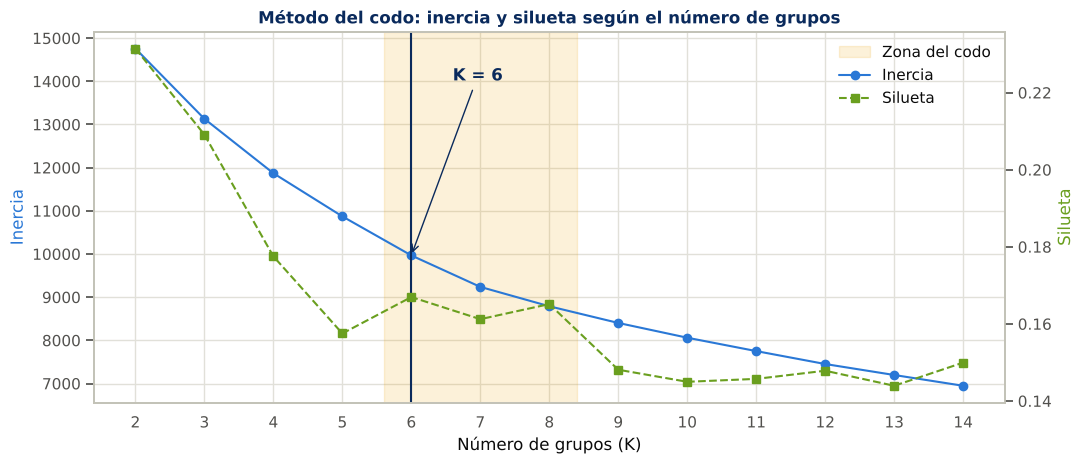

,inercia,silueta,distancia_a_la_recta,grupo_mas_pequeno
k,,,,
2,14759.259,0.231,0.000,1182
3,13131.208,0.209,0.125,654
4,11870.668,0.178,0.203,263
5,10871.128,0.158,0.248,243
6,9966.776,0.167,0.280,120
7,9237.926,0.161,0.290,89
8,8789.217,0.165,0.264,74
9,8402.935,0.148,0.230,71
10,8060.923,0.145,0.191,70


In [9]:
k_vals = curva.index.values.astype(float)
inercia = curva['inercia'].values
xn = (k_vals - k_vals.min()) / (k_vals.max() - k_vals.min())
yn = (inercia - inercia.min()) / (inercia.max() - inercia.min())
curva['distancia_a_la_recta'] = np.abs(yn - (1 - xn))      # cuanto mayor, más "codo" hay en ese punto

umbral = 0.9 * curva['distancia_a_la_recta'].max()
zona_codo = curva.index[curva['distancia_a_la_recta'] >= umbral].tolist()
K = int(curva.loc[zona_codo, 'silueta'].idxmax())
print(f"Zona del codo (≥90 % de la distancia máxima a la recta): K = {zona_codo}")
print(f"Dentro de esa zona, la mejor silueta es la de K = {K}")

fig, ax1 = plt.subplots(figsize=(11, 4.8))
ax1.axvspan(min(zona_codo) - 0.4, max(zona_codo) + 0.4, color=DSMARKET_GOLD, alpha=0.15, label='Zona del codo')
ax1.plot(curva.index, curva['inercia'], marker='o', color=DSMARKET_BLUE, label='Inercia')
ax1.set_xlabel('Número de grupos (K)')
ax1.set_ylabel('Inercia', color=DSMARKET_BLUE)
ax2 = ax1.twinx()
ax2.plot(curva.index, curva['silueta'], marker='s', linestyle='--', color=DSMARKET_GREEN, label='Silueta')
ax2.set_ylabel('Silueta', color=DSMARKET_GREEN)
ax2.grid(False)
ax1.axvline(K, color=DSMARKET_NAVY, linewidth=1.5)
ax1.annotate(f'K = {K}', xy=(K, curva.loc[K, 'inercia']), xytext=(K + 0.6, curva['inercia'].max() * 0.95),
             color=DSMARKET_NAVY, fontweight='bold', arrowprops=dict(arrowstyle='->', color=DSMARKET_NAVY))
ax1.set_xticks(list(K_RANGO))
lineas = ax1.get_legend_handles_labels(); lineas2 = ax2.get_legend_handles_labels()
ax1.legend(lineas[0] + lineas2[0], lineas[1] + lineas2[1], frameon=False, loc='upper right')
ax1.set_title('Método del codo: inercia y silueta según el número de grupos')
plt.tight_layout()
plt.show()

curva[['inercia', 'silueta', 'distancia_a_la_recta', 'grupo_mas_pequeno']].round(3)

**Decisión: K = 6.**

- **Codo:** la curva de la inercia es suave, sin un quiebre brusco (lo habitual con datos de comportamiento, donde los productos no forman islas separadas sino un continuo). Medida de forma objetiva, la zona del codo (los puntos que más se alejan de la recta) abarca de **6 a 8 grupos**.
- **Silueta:** dentro de esa zona, K = 6 presenta la mejor silueta (0,167).
- **Tamaño:** el grupo más pequeño tiene 120 productos, suficiente para una campaña propia.

La silueta es más alta con 2, 3 o 4 grupos, pero esas particiones solo separan «productos que venden mucho» de «productos que venden poco»: no distinguen el fin de semana, la Navidad ni los eventos, que es precisamente lo que necesita marketing. La silueta moderada (0,17) se explica por el mismo motivo: los productos se distribuyen de forma continua y los grupos tienen bordes difusos. Se busca una partición útil y estable, lo cual se comprueba en el siguiente apartado.

### 4.5. Modelo final y estabilidad

Se entrena K-Means con el K elegido. Dado que K-Means parte de centros aleatorios, se comprueba que el resultado no dependa del azar: se repite con 10 semillas distintas y cada resultado se compara con el primero mediante el **índice de Rand ajustado** (ARI: 1 = grupos idénticos, 0 = coincidencia aleatoria).

In [10]:
modelos = [KMeans(n_clusters=K, random_state=s, n_init=50).fit(X_items) for s in range(10)]
ari = [adjusted_rand_score(modelos[0].labels_, m.labels_) for m in modelos[1:]]
print(f"ARI medio entre 10 semillas: {np.mean(ari):.2f} (mínimo {np.min(ari):.2f})")

km_final = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=50).fit(X_items)
item_feat['grupo_raw'] = km_final.labels_

ARI medio entre 10 semillas: 0.98 (mínimo 0.96)


### 4.6. Ficha de los grupos y nombres

Cada grupo se resume en una **ficha**: tamaño, valores medios de las variables utilizadas y, además, **variables que no intervinieron en el agrupamiento** (categoría y facturación). Estas últimas permiten describir qué productos contiene cada grupo.

**Criterio de nombres.** Cada nombre describe el **rasgo de comportamiento que define al grupo** (ritmo de venta, momento de compra o precio), puesto que el agrupamiento se realizó por comportamiento y no por categoría. La categoría se indica solo como contexto en la descripción del grupo, ya que en los grupos mixtos no es un rasgo definitorio.

Para que los nombres no dependan del número que K-Means asigna a cada grupo (que cambia según la semilla), se asignan mediante reglas sobre la propia ficha, aplicadas en este orden:

| Orden | Regla | Nombre |
|---|---|---|
| 1 | Mayor cociente diciembre / resto del año | **Pico de diciembre** |
| 2 | Mayor precio medio | **Precio alto, pocas unidades** |
| 3 | Más unidades por día | **Alta rotación diaria** |
| 4 | Mayor proporción de días sin venta | **Venta esporádica con pico en eventos** |
| 5 | Mayor cociente fin de semana / entre semana | **Pico de fin de semana** |
| 6 | Grupo restante | **Rotación baja sin picos** |

In [11]:
perfil = item_feat.groupby('grupo_raw').agg(
    productos=('total_units', 'size'), unidades_medias=('units_dia', 'mean'),
    zero_frac=('zero_frac', 'mean'), weekend_lift=('weekend_lift', 'mean'), dec_lift=('dec_lift', 'mean'),
    event_lift=('event_lift', 'mean'), avg_price=('avg_price', 'mean'), facturacion=('facturacion', 'sum'))

# --- nombres asignados por reglas sobre la ficha (independientes de la numeración de K-Means) ---
pendientes = list(perfil.index)
def tomar(col, mayor=True):
    g = perfil.loc[pendientes, col].idxmax() if mayor else perfil.loc[pendientes, col].idxmin()
    pendientes.remove(g)
    return g
asignacion = {}
asignacion[tomar('dec_lift')] = 'Pico de diciembre'                       # mayor cociente diciembre / resto del año
asignacion[tomar('avg_price')] = 'Precio alto, pocas unidades'            # mayor precio medio
asignacion[tomar('unidades_medias')] = 'Alta rotación diaria'             # más unidades por día
asignacion[tomar('zero_frac')] = 'Venta esporádica con pico en eventos'   # mayor proporción de días sin venta
asignacion[tomar('weekend_lift')] = 'Pico de fin de semana'               # mayor cociente fin de semana / entre semana
asignacion[tomar('weekend_lift')] = 'Rotación baja sin picos'             # grupo restante
assert not pendientes, "quedan grupos sin nombre"

# numeración final: de mayor a menor facturación
orden = perfil['facturacion'].sort_values(ascending=False).index
nuevo_id = {g: i for i, g in enumerate(orden)}
item_feat['grupo'] = item_feat['grupo_raw'].map(nuevo_id)
item_feat['nombre_grupo'] = item_feat['grupo_raw'].map(asignacion)
NOMBRES = dict(zip(item_feat['grupo'], item_feat['nombre_grupo']))
NOMBRES = {k: NOMBRES[k] for k in sorted(NOMBRES)}
for g, n in NOMBRES.items():
    print(f"Grupo {g}: {n}")

Grupo 0: Alta rotación diaria
Grupo 1: Pico de fin de semana
Grupo 2: Rotación baja sin picos
Grupo 3: Precio alto, pocas unidades
Grupo 4: Venta esporádica con pico en eventos
Grupo 5: Pico de diciembre


In [12]:
g = item_feat.groupby('grupo')
ficha = pd.DataFrame({
    'Grupo': [f'{i} · {NOMBRES[i]}' for i in sorted(NOMBRES)],
    'Productos': g.size().values,
    '% del catálogo': (g.size() / len(item_feat) * 100).values,
    '% de la facturación': (g['facturacion'].sum() / item_feat['facturacion'].sum() * 100).values,
    'Unidades por día': g['units_dia'].mean().values,
    'Días a la venta': g['dias_activo'].mean().values,
    '% días sin venta': (g['zero_frac'].mean() * 100).values,
    'Fin de semana vs. entre semana': g['weekend_lift'].mean().values,
    'Diciembre vs. resto del año': g['dec_lift'].mean().values,
    'Eventos vs. día normal': g['event_lift'].mean().values,
    'Precio medio ($)': g['avg_price'].mean().values,
}).set_index('Grupo')
categorias = pd.crosstab(item_feat['grupo'], item_feat['category'], normalize='index') * 100
categorias.index = ficha.index
categorias.columns = [f'% {c}' for c in categorias.columns]
ficha = ficha.join(categorias)

(ficha.T.style.format('{:,.2f}')
      .background_gradient(cmap=dsmarket_blues_cmap, axis=1))

Grupo,0 · Alta rotación diaria,1 · Pico de fin de semana,2 · Rotación baja sin picos,"3 · Precio alto, pocas unidades",4 · Venta esporádica con pico en eventos,5 · Pico de diciembre
Productos,679.00,882.00,745.00,218.00,405.00,120.00
% del catálogo,22.27,28.93,24.43,7.15,13.28,3.94
% de la facturación,42.44,25.43,14.74,11.08,4.23,2.08
Unidades por día,37.39,8.10,6.04,4.59,2.60,5.39
Días a la venta,"1,631.93","1,574.90","1,560.83","1,484.08","1,575.57","1,450.28"
% días sin venta,5.25,9.31,12.47,17.21,38.83,31.17
Fin de semana vs. entre semana,1.29,1.42,1.21,1.35,1.34,1.31
Diciembre vs. resto del año,0.93,0.93,0.95,0.96,0.78,1.89
Eventos vs. día normal,1.12,1.27,0.96,1.10,1.26,1.01
Precio medio ($),2.62,5.22,4.91,17.44,6.13,5.37


**Los 6 grupos.** El nombre de cada grupo describe su comportamiento de compra; la categoría predominante se indica en la descripción cuando existe.

| Grupo | Qué define al grupo | Productos que contiene |
|---|---|---|
| **0 · Alta rotación diaria** | Venden mucho (37 unidades al día entre las 10 tiendas) y casi todos los días (5 % de días sin venta). Son el **42 % de la facturación**. | 72 % supermercado; los más baratos (2,6 $) |
| **1 · Pico de fin de semana** | Venden un 42 % más el fin de semana, el valor más alto de todos los grupos, y también suben en los eventos. Segundo grupo en facturación (25 %). | 45 % hogar y jardín |
| **2 · Rotación baja sin picos** | Venden poco (6 unidades al día) y sin picos: son los que menos reaccionan al fin de semana, a diciembre y a los eventos. Representan el 24 % del catálogo y el 15 % de la facturación. | Mixto (52 % supermercado, 26 % hogar, 21 % accesorios) |
| **3 · Precio alto, pocas unidades** | Los más caros (17,4 $ de media, más del triple que el resto). Pocas unidades, pero el 11 % de la facturación. | 48 % accesorios y 43 % hogar |
| **4 · Venta esporádica con pico en eventos** | El 39 % de los días en que están a la venta no venden nada, pero en SuperBowl, Easter y Labor Day venden un **26 % más** que un día normal (en parte porque dos de esos días son domingo). Representan el 13 % del catálogo y solo el 4 % de la facturación. | Mixto (49 % hogar, 28 % supermercado, 23 % accesorios) |
| **5 · Pico de diciembre** | En diciembre venden **casi el doble** (1,89 veces) que el resto del año. | Mixto (38 % accesorios, 35 % supermercado, 28 % hogar): mesa y regalo |

**Para Joelle:**
- Cada grupo requiere una campaña distinta: el grupo 1 se trabaja los viernes y sábados, el grupo 4 en las fechas señaladas del calendario y el grupo 5 en diciembre.
- Para medir si una campaña ha funcionado, conviene comparar cada producto con su grupo y no con el total de la tienda: cada grupo incorpora su propio nivel «normal» de ventas y de estacionalidad.
- El grupo 4 es el candidato para revisar el surtido: ocupa el 13 % del catálogo y aporta el 4 % de la facturación.

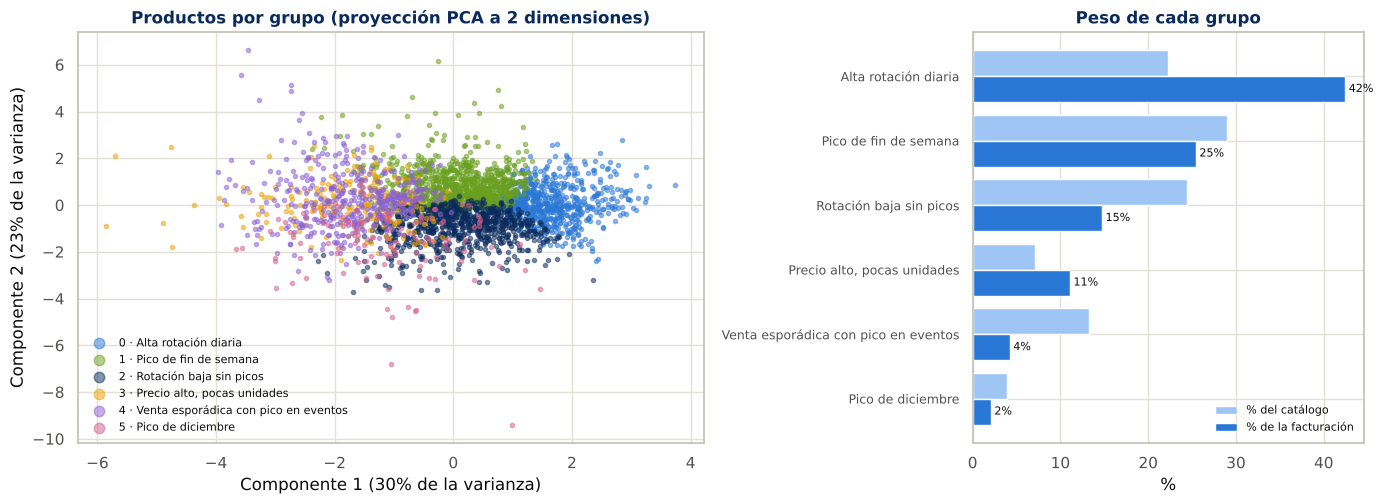

Las dos componentes resumen el 52% de la información de las 6 variables.


In [13]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(X_items)
var_exp = pca.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={'width_ratios': [1.6, 1]})
ax = axes[0]
for gr in sorted(NOMBRES):
    m = (item_feat['grupo'] == gr).values
    ax.scatter(coords[m, 0], coords[m, 1], s=9, alpha=0.5, color=CLUSTER_PALETTE[gr], label=f'{gr} · {NOMBRES[gr]}')
ax.set_xlabel(f'Componente 1 ({var_exp[0]:.0%} de la varianza)')
ax.set_ylabel(f'Componente 2 ({var_exp[1]:.0%} de la varianza)')
ax.set_title('Productos por grupo (proyección PCA a 2 dimensiones)')
ax.legend(frameon=False, markerscale=2.5, fontsize=8, loc='best')

ax2 = axes[1]
tabla = ficha[['% del catálogo', '% de la facturación']].iloc[::-1]
y = np.arange(len(tabla))
ax2.barh(y + 0.2, tabla['% del catálogo'], height=0.4, color='#9ec5f4', label='% del catálogo')
ax2.barh(y - 0.2, tabla['% de la facturación'], height=0.4, color=DSMARKET_BLUE, label='% de la facturación')
ax2.set_yticks(y); ax2.set_yticklabels([t.split(' · ')[1] for t in tabla.index], fontsize=9)
for yy, v in zip(y - 0.2, tabla['% de la facturación']):
    ax2.text(v, yy, f' {v:.0f}%', va='center', fontsize=8)
ax2.set_xlabel('%')
ax2.set_title('Peso de cada grupo')
ax2.legend(frameon=False, fontsize=8, loc='lower right')
plt.tight_layout()
plt.show()
print(f"Las dos componentes resumen el {var_exp.sum():.0%} de la información de las {len(FEAT_COLS)} variables.")

### 4.7. Respuesta a Joelle: ¿5, 10 o 20 grupos?

Joelle propuso tres valores, que se comparan con el elegido por el codo:

In [14]:
extra = []
for k in [5, K, 10, 20]:
    if k in curva.index:
        r = curva.loc[k]
        extra.append({'K': k, 'silueta': r['silueta'], 'grupo más pequeño': int(r['grupo_mas_pequeno']), 'origen': 'codo' if k == K else 'propuesta de Joelle'})
    else:
        km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=50).fit(X_items)
        extra.append({'K': k, 'silueta': silhouette_score(X_items, km.labels_),
                      'grupo más pequeño': int(np.bincount(km.labels_).min()), 'origen': 'propuesta de Joelle'})
pd.DataFrame(extra).set_index('K').round(3)

,silueta,grupo más pequeño,origen
K,,,
5,0.158,243,propuesta de Joelle
6,0.167,120,codo
10,0.145,70,propuesta de Joelle
20,0.134,1,propuesta de Joelle


**Respuesta a Joelle: 6 grupos.**

- **5 grupos** se aproxima, pero junta el grupo de diciembre con otros productos y su señal se pierde.
- **10 grupos** afina algo más (separa un núcleo de eventos todavía más extremo), pero empeora la silueta (0,145) y divide los grupos grandes de supermercado y hogar en subgrupos que solo se diferencian en matices. Para planificar campañas, 6 grupos resulta más manejable.
- **20 grupos** genera un grupo con **un solo producto**: deja de ser una segmentación y pasa a ser una lista.

Además, una única segmentación evita el problema de tener dos clasificaciones distintas del mismo producto (una con 5 grupos y otra con 10) que no encajan entre sí.

### 4.8. Un caso que ilustra el grupo «Pico de diciembre»: `SUPERMARKET_3_069`

Dentro del grupo «Pico de diciembre» destaca un producto con la mayor subida de diciembre de todo el catálogo.

Producto con más subida en diciembre: SUPERMARKET_3_069 (grupo 5 · Pico de diciembre)
Vende 7.7 veces más en diciembre que el resto del año.

Sus 5 mejores días en cinco años:
2014-12-31    981
2012-12-31    906
2013-12-31    770
2015-12-31    756
2011-12-24    418


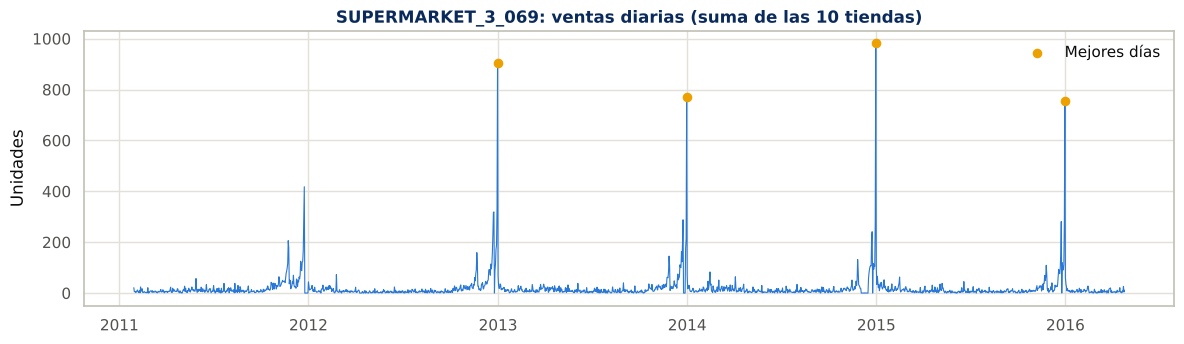

In [15]:
caso = item_feat['dec_lift'].idxmax()
print(f"Producto con más subida en diciembre: {caso} (grupo {item_feat.loc[caso, 'grupo']} · {item_feat.loc[caso, 'nombre_grupo']})")
print(f"Vende {item_feat.loc[caso, 'dec_lift']:.1f} veces más en diciembre que el resto del año.")
print()
serie = pd.Series(item_day.loc[caso].values, index=dates_of_days.values)
print("Sus 5 mejores días en cinco años:")
print(serie.sort_values(ascending=False).head(5).to_string())

fig, ax = plt.subplots(figsize=(12, 3.6))
ax.plot(serie.index, serie.values, color=DSMARKET_BLUE, linewidth=0.8)
top = serie.sort_values(ascending=False).head(4)
ax.scatter(top.index, top.values, color=DSMARKET_GOLD, zorder=3, s=35, label='Mejores días')
ax.set_title(f'{caso}: ventas diarias (suma de las 10 tiendas)')
ax.set_ylabel('Unidades')
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

`SUPERMARKET_3_069` vende una mediana de 8 unidades al día entre las 10 tiendas, pero sus cuatro mejores días en cinco años son **cuatro 31 de diciembre**. Es, con toda probabilidad, un producto de Nochevieja.

Este caso permite explicar el grupo de diciembre y deja dos avisos para las tareas siguientes:
- **Predicción (Tarea 3):** un modelo que no tenga en cuenta el calendario lo subestimará en diciembre.
- **Reposición (Tarea 4):** el stock de seguridad de estos productos no puede calcularse con la demanda media del año; requieren una regla de temporada o se agotarán precisamente el 31.

### 4.9. Guardar la segmentación

Se guardan dos archivos para su uso posterior:
- `segmentacion_productos.csv`: el grupo de cada producto, utilizado para describir el error de la predicción por tipo de producto (Tarea 3) y en la reposición (Tarea 4).
- `perfil_productos.csv`: las variables de comportamiento de cada producto (las de la sección 4.1), utilizadas por el almacén de datos para el análisis de grupos en el cuadro de mando.

In [16]:
os.makedirs('cache_forecast', exist_ok=True)
salida = item_feat[['grupo', 'nombre_grupo']]
salida.to_csv('cache_forecast/segmentacion_productos.csv')
print(f"Guardado cache_forecast/segmentacion_productos.csv: {len(salida)} productos")

# Perfil de comportamiento de cada producto (alimenta el análisis de grupos del cuadro de mando)
perfil_cols = ['grupo', 'nombre_grupo', 'category', 'department', 'total_units', 'dias_activo', 'units_dia',
               'zero_frac', 'weekend_lift', 'dec_lift', 'event_lift', 'avg_price', 'facturacion']
item_feat[perfil_cols].round(4).to_csv('cache_forecast/perfil_productos.csv')
print(f"Guardado cache_forecast/perfil_productos.csv: {len(item_feat)} productos, {len(perfil_cols)} columnas")
salida['nombre_grupo'].value_counts()

Guardado cache_forecast/segmentacion_productos.csv: 3049 productos
Guardado cache_forecast/perfil_productos.csv: 3049 productos, 13 columnas


nombre_grupo
Pico de fin de semana                   882
Rotación baja sin picos                 745
Alta rotación diaria                    679
Venta esporádica con pico en eventos    405
Precio alto, pocas unidades             218
Pico de diciembre                       120
Name: count, dtype: int64

## 5. Tiendas: comparación directa en lugar de clustering

### 5.1. Por qué no se agrupan las tiendas con un algoritmo

Joelle consultó si agrupar tiendas también tendría sentido. **Con estos datos, no**, por tres motivos:

1. **Solo hay 10 tiendas.** Un algoritmo de agrupamiento resulta útil cuando hay demasiados elementos para compararlos a simple vista, como los 3.049 productos. Diez tiendas caben en una tabla.
2. **Habría más variables que tiendas.** Describir el perfil de una tienda requiere unas 12 variables (volumen, estabilidad, fin de semana, diciembre, precio y el peso de cada uno de los 7 departamentos). Con 12 dimensiones y 10 puntos, las distancias pierden sentido, es lo que se conoce como **maldición de la dimensionalidad**. Cualquier agrupación resultaría inestable y dependería de qué tiendas entren en el cálculo.
3. **Lo que interesa a negocio se aprecia mejor comparando directamente**: qué tienda se parece a cuál y en qué.

Por ello, la respuesta a Joelle se construye con una **tabla comparativa** y una medida de **parecido entre tiendas**.

In [17]:
store_day = sales.groupby('store_code')[day_cols].sum()
vals_s = store_day.values.astype(float)
media_s = vals_s.mean(axis=1)

store_feat = pd.DataFrame({
    'ventas_dia': media_s,
    'cv_daily': vals_s.std(axis=1) / media_s,
    'weekend_lift': vals_s[:, is_weekend].mean(axis=1) / vals_s[:, ~is_weekend].mean(axis=1),
    'dec_lift': vals_s[:, is_dec].mean(axis=1) / vals_s[:, ~is_dec].mean(axis=1),
}, index=store_day.index)

# índice de precio: cuánto más cara o barata es la tienda que la media de cada producto (EDA, sección 10.1)
precio_item_tienda = prices_clean.groupby(['item', 'store_code'])['sell_price'].mean().unstack('store_code')
relativo = precio_item_tienda.div(precio_item_tienda.mean(axis=1), axis=0)
store_feat['indice_precio_pct'] = (relativo.mean(axis=0) - 1) * 100

# peso de cada categoría en las unidades vendidas
tot = sales[['store_code', 'category']].assign(u=sales[day_cols].sum(axis=1))
mix = tot.groupby(['store_code', 'category'])['u'].sum().unstack('category')
mix = mix.div(mix.sum(axis=1), axis=0) * 100
store_feat['pct_supermarket'] = mix['SUPERMARKET']
store_feat['pct_hogar'] = mix['HOME_&_GARDEN']
store_feat['pct_accesorios'] = mix['ACCESORIES']

meta_t = sales[['store_code', 'store', 'region']].drop_duplicates().set_index('store_code')
store_feat = meta_t.join(store_feat)
store_feat['store'] = store_feat['store'].str.replace('_', ' ')

ETIQUETAS = {'ventas_dia': 'Unidades por día', 'cv_daily': 'Variabilidad diaria',
             'weekend_lift': 'Fin de semana vs. entre semana', 'dec_lift': 'Diciembre vs. resto del año',
             'indice_precio_pct': 'Índice de precio (%)', 'pct_supermarket': '% supermercado',
             'pct_hogar': '% hogar', 'pct_accesorios': '% accesorios'}
tabla_t = store_feat.set_index(['region', 'store']).rename(columns=ETIQUETAS)
tabla_t.style.format('{:,.2f}').background_gradient(cmap=dsmarket_blues_cmap, axis=0)

### 5.2. Mapa de calor: en qué se diferencia cada tienda

Cada celda indica cuánto se aleja la tienda de la media de las 10 en esa variable (en desviaciones típicas): azul por encima de la media y dorado por debajo.

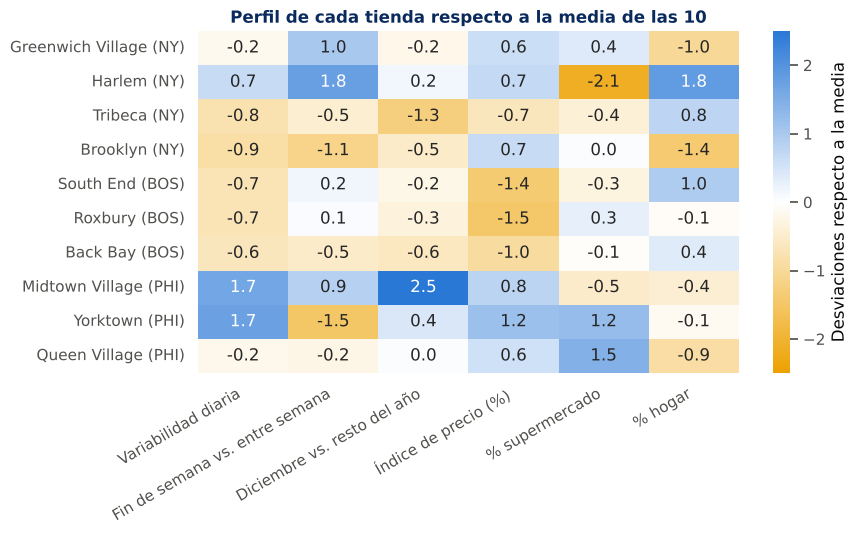

In [18]:
PERFIL_T = ['cv_daily', 'weekend_lift', 'dec_lift', 'indice_precio_pct', 'pct_supermarket', 'pct_hogar']
z = (store_feat[PERFIL_T] - store_feat[PERFIL_T].mean()) / store_feat[PERFIL_T].std()
z.index = store_feat['store'] + ' (' + store_feat['region'].map({'New York': 'NY', 'Boston': 'BOS', 'Philadelphia': 'PHI'}) + ')'

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.heatmap(z.rename(columns=ETIQUETAS), annot=True, fmt='.1f', cmap=DIVERGENTE, center=0,
            vmin=-2.5, vmax=2.5, cbar_kws={'label': 'Desviaciones respecto a la media'}, ax=ax)
ax.set_title('Perfil de cada tienda respecto a la media de las 10')
ax.set_ylabel('')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

### 5.3. ¿Qué tienda se parece más a cuál?

La distancia entre tiendas se mide con las variables de **perfil** de la tabla anterior. El volumen de ventas se excluye porque mide el tamaño de la tienda y no su forma de vender: una tienda grande y una pequeña pueden tener el mismo perfil.

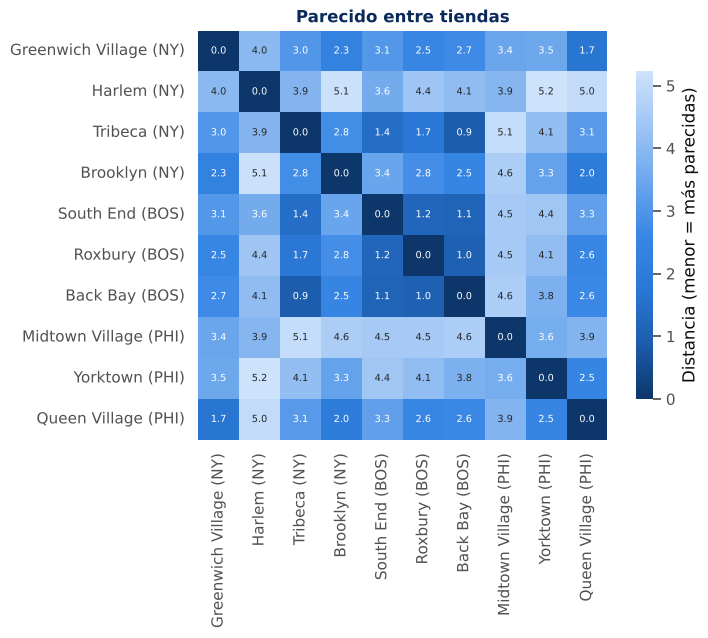

,Más parecida,Distancia,Segunda más parecida
Tienda,,,
Greenwich Village (NY),Queen Village (PHI),1.66,Brooklyn (NY)
Harlem (NY),South End (BOS),3.61,Tribeca (NY)
Tribeca (NY),Back Bay (BOS),0.90,South End (BOS)
Brooklyn (NY),Queen Village (PHI),1.98,Greenwich Village (NY)
South End (BOS),Back Bay (BOS),1.12,Roxbury (BOS)
Roxbury (BOS),Back Bay (BOS),1.01,South End (BOS)
Back Bay (BOS),Tribeca (NY),0.90,Roxbury (BOS)
Midtown Village (PHI),Greenwich Village (NY),3.45,Yorktown (PHI)
Yorktown (PHI),Queen Village (PHI),2.52,Brooklyn (NY)


In [19]:
D = pd.DataFrame(cdist(z.values, z.values), index=z.index, columns=z.index)
parecido = []
for t in D.index:
    otras = D.loc[t].drop(t).sort_values()
    parecido.append({'Tienda': t, 'Más parecida': otras.index[0], 'Distancia': otras.iloc[0],
                     'Segunda más parecida': otras.index[1]})
parecido = pd.DataFrame(parecido).set_index('Tienda')

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(D, annot=True, fmt='.1f', cmap=dsmarket_blues_cmap.reversed(), square=True,
            cbar_kws={'label': 'Distancia (menor = más parecidas)', 'shrink': 0.8}, ax=ax, annot_kws={'size': 7})
ax.set_title('Parecido entre tiendas')
ax.set_xlabel(''); ax.set_ylabel('')
plt.tight_layout()
plt.show()

# se guarda la tienda más parecida de cada una: la usan el almacén de datos y la aplicación
codigo = dict(zip(z.index, store_feat.index))
pd.DataFrame({'store_code': [codigo[t] for t in parecido.index],
              'tienda_mas_parecida': [codigo[t] for t in parecido['Más parecida']]}
             ).to_csv('cache_forecast/tienda_mas_parecida.csv', index=False)
parecido.round(2)

**Qué se observa al comparar las tiendas directamente:**

- **Tribeca (New York) se parece más a las tiendas de Boston que a las de su propia ciudad.** Su tienda más parecida es Back Bay y la segunda, South End, ambas de Boston. Comparte con ellas el precio por debajo de la media (−0,39 %, frente a −0,55 % / −0,85 % en Boston y +0,36 % / +0,40 % en el resto de New York), la baja variabilidad diaria y un fin de semana moderado.
- **Las tres tiendas de Boston se parecen mucho entre sí** (distancias de entre 1,01 y 1,12, solo por detrás de la pareja Tribeca–Back Bay, con 0,90). Boston es la ciudad más homogénea, igual que se observó en el EDA con los productos más vendidos.
- **Harlem y Midtown Village no se parecen a ninguna otra tienda.** Harlem presenta el fin de semana más fuerte (+50 %) y el mayor peso de hogar (28 %). Midtown Village es la única tienda que vende más en diciembre que el resto del año y, junto con Yorktown, la de ventas más irregulares.
- **El precio separa por ciudad:** Boston y Tribeca son las tiendas más baratas, y las de Filadelfia, las más caras. Las diferencias son inferiores al 1 %.

**Conclusión para Michelle:** el perfil de una tienda no viene determinado por su ciudad. Si se abre una tienda nueva, la referencia para su surtido y su previsión inicial debería ser la tienda existente que se espere más parecida (por tipo de zona y de clientela), y no la media de su ciudad.

## 6. Conclusiones y uso en las siguientes tareas

| Pedido | Respuesta |
|---|---|
| ¿Cuántos grupos de productos? ¿5, 10 o 20? | **6**, elegidos con el método del codo y la silueta, y estables (ARI 0,98 entre 10 semillas). |
| ¿Qué es cada grupo? | Una ficha con un nombre que describe el comportamiento de compra del grupo y los productos que contiene (sección 4.6). |
| ¿Tiene sentido agrupar tiendas? | **No con un algoritmo**: 10 tiendas y más variables que tiendas. Se comparan directamente (sección 5): Tribeca se comporta como una tienda de Boston, y Harlem y Midtown Village no se parecen a ninguna otra. |

**Decisiones de método, resumidas:**
- Todas las variables se miden **desde la primera venta** de cada producto, para no confundir un lanzamiento tardío con un producto de venta ocasional.
- 6 variables de comportamiento; se eliminan `cv_daily` (repite `zero_frac`) y `trend` (describe el ciclo de vida, no el momento de compra).
- `StandardScaler`, porque `RobustScaler` aísla productos sueltos en grupos de uno.
- K-Means con K elegido por el codo (K de 2 a 14) y la silueta.
- Los nombres de grupo describen el comportamiento de compra y se asignan mediante reglas sobre la ficha.

**Qué pasa a las tareas siguientes:**
- **Tarea 3 (predicción):** el grupo de producto se probó como variable del modelo, pero el experimento `03b` mostró que no mejora la predicción, por lo que el modelo final no lo utiliza; se emplea para describir el error por tipo de producto. Tampoco se utiliza ningún grupo de tiendas: la tienda y la ciudad figuran en el modelo como variables propias.
- **Tarea 4 (reposición):** los grupos ayudan a describir cada producto, pero la política de reposición se decide **simulando su coste**, y no por el grupo ni por el error de predicción: esa simulación muestra que el modelo ahorra más precisamente en los productos de venta irregular. El grupo «Pico de diciembre» sí requiere una regla de temporada.

**Limitación:** la silueta es moderada (0,17) porque los productos forman un continuo y no grupos separados. Los grupos constituyen una forma útil y estable de ordenar el catálogo, y no «tipos naturales» de producto.